# Week 7: K-Nearest Neighbors & Distance Measures

## Student Practice Notebook

**Name:** K. Satya Ganesh  
**Roll Number (Registration Number):** AP24110010736  
**Date:** 09-10-2026

## Learning Objectives

After completing this lab, you will be able to:

- Compute Euclidean and Manhattan distance between two points, by hand and in code
- Explain how KNN classifies a new point using its nearest neighbors
- Fit a `KNeighborsClassifier` correctly (split → scale on train only → fit)
- Explain why K matters, and identify overfitting/underfitting as K changes
- Solve a KNN numerical problem by hand — the kind you'll see in a written exam

### Why this week matters
Every model you've built so far (Weeks 5-6) assumed an equation. KNN assumes nothing — it just asks "what do my nearest neighbors look like?" It's the simplest possible classifier, and understanding *why* it works (and where it breaks) builds the intuition you'll need for every distance-based method later in the course.


## Part 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

%matplotlib inline
np.random.seed(1)


In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## Part 1 — Distance Measures

KNN's entire decision rule is "find the closest points." "Closest" needs a precise definition — that's what a distance metric gives us.

### 1.1 Demo: Euclidean and Manhattan distance, by hand


In [4]:
p1 = np.array([5.1, 3.5, 1.4, 0.2])   # a sample flower's 4 measurements
p2 = np.array([6.4, 3.2, 4.5, 1.5])   # a different flower

euclidean = np.sqrt(np.sum((p1 - p2) ** 2))
manhattan = np.sum(np.abs(p1 - p2))

print('Euclidean distance:', euclidean)
print('Manhattan distance:', manhattan)


Euclidean distance: 3.6166282640050254
Manhattan distance: 6.000000000000001


**Predict, then think:** Euclidean distance is always ≤ or ≥ Manhattan distance for the same two points (pick one) — why? Think about what happens along a single axis vs. across multiple axes at once.

*Your answer:*

Euclidean distance is always **≤ (less than or equal to)** Manhattan distance.

Manhattan adds up the difference along each axis one by one, like walking along city blocks. Euclidean goes in a straight line between the two points, and a straight line is the shortest path. If the two points differ on only one axis, both distances are equal. As soon as they differ on two or more axes, the straight line is shorter. For our two flowers, Euclidean is about 3.62 and Manhattan is about 6.0, so it matches.

### Student Practice — Minkowski distance

The Minkowski distance generalizes both: $d(p,q) = \left(\sum |p_i - q_i|^p\right)^{1/p}$. Euclidean is Minkowski with $p=2$; Manhattan is Minkowski with $p=1$.

Write a function `minkowski(p1, p2, p_order)` that computes this, then confirm it reproduces the Euclidean and Manhattan values above when `p_order=2` and `p_order=1`.


In [5]:
def minkowski(p1, p2, p_order):
    # take the absolute difference, raise to the power p, add them up, then take the p-th root
    return np.sum(np.abs(p1 - p2) ** p_order) ** (1 / p_order)

print('Minkowski (p=2):', minkowski(p1, p2, 2))
print('Euclidean      :', euclidean)
print('Minkowski (p=1):', minkowski(p1, p2, 1))
print('Manhattan      :', manhattan)

print('p=2 matches Euclidean?', np.isclose(minkowski(p1, p2, 2), euclidean))
print('p=1 matches Manhattan?', np.isclose(minkowski(p1, p2, 1), manhattan))

Minkowski (p=2): 3.6166282640050254
Euclidean      : 3.6166282640050254
Minkowski (p=1): 6.000000000000001
Manhattan      : 6.000000000000001
p=2 matches Euclidean? True
p=1 matches Manhattan? True


## Part 2 — Fitting a KNN Classifier

Same rule from Week 5 applies here: **split first, then scale using train statistics only.** KNN is a distance-based method, so unscaled features (e.g. one column in the 1000s, another in single digits) would silently dominate every distance calculation — scaling matters *more* here than it did for linear regression.


In [6]:
X = df[iris.feature_names]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Accuracy (k=5): 0.9333333333333333


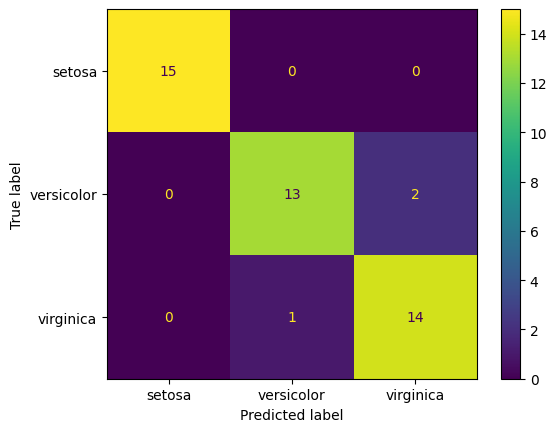

In [7]:
knn5 = KNeighborsClassifier(n_neighbors=5)
knn5.fit(X_train_scaled, y_train)

y_pred = knn5.predict(X_test_scaled)
print('Accuracy (k=5):', accuracy_score(y_test, y_pred))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=iris.target_names).plot()
plt.show()


### Student Practice — try k=1

Fit a `KNeighborsClassifier` with `n_neighbors=1` on the same scaled data. Print its test accuracy and confusion matrix. Is it better or worse than k=5?


Accuracy (k=1): 0.9333333333333333
Accuracy (k=5): 0.9333333333333333


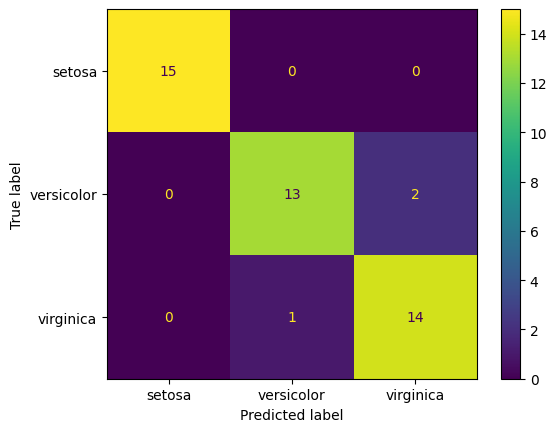

In [8]:
knn1 = KNeighborsClassifier(n_neighbors=1)
knn1.fit(X_train_scaled, y_train)

y_pred1 = knn1.predict(X_test_scaled)
print('Accuracy (k=1):', accuracy_score(y_test, y_pred1))
print('Accuracy (k=5):', accuracy_score(y_test, y_pred))   # from the cell above, to compare

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred1), display_labels=iris.target_names).plot()
plt.show()

*Your answer:* With k=1 the test accuracy is 0.933, which is exactly the same as k=5 (0.933). The confusion matrix is also the same for both: 3 flowers are wrong (2 versicolor predicted as virginica, 1 virginica predicted as versicolor). So k=1 is **not better and not worse** than k=5 on this test set. The difference between them is that k=1 has train accuracy of 1.0 (it memorizes), so it is the riskier choice on new data.

## Part 3 — Why K Matters

### Demo: sweep K from 1 to 30


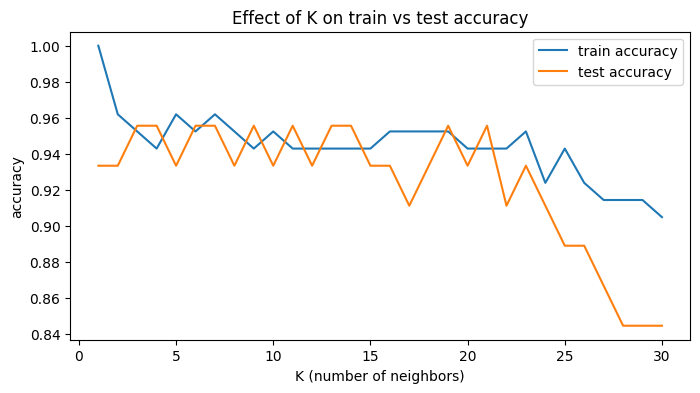

In [9]:
train_acc, test_acc = [], []
k_values = range(1, 31)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    train_acc.append(accuracy_score(y_train, knn.predict(X_train_scaled)))
    test_acc.append(accuracy_score(y_test, knn.predict(X_test_scaled)))

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), train_acc, label='train accuracy')
plt.plot(list(k_values), test_acc, label='test accuracy')
plt.xlabel('K (number of neighbors)')
plt.ylabel('accuracy')
plt.legend()
plt.title('Effect of K on train vs test accuracy')
plt.show()


**Reflection:** This should look familiar from Week 6. At K=1, is the model closer to overfitting or underfitting? What about at K=30? Connect this explicitly to bias and variance.

*Your answer:*

**At K=1** the model is closer to **overfitting**. The train accuracy is 1.0 because every training point is its own nearest neighbor, but the test accuracy is lower (about 0.93). That gap means it is memorizing the training data, noise included. This is low bias but high variance, because the decision boundary changes a lot if the training data changes a little.

**At K=30** the model is closer to **underfitting**. Both train accuracy (about 0.90) and test accuracy (about 0.84) have dropped. With 30 neighbors the vote is too smooth, and points from other classes get pulled in. This is high bias but low variance, because the model is too simple to follow the real boundary between the species.

So small K = high variance, and large K = high bias. A medium K sits in between. It is the same shape as Week 6, but here K is the knob instead of polynomial degree.

### Student Practice — pick the best K

From the sweep above, find the K with the highest test accuracy. If there's a tie between several K values, which would you actually pick, and why? (Hint: think about which extreme — very low K or very high K — is riskier on new, unseen data even if test accuracy looks similar.)


In [10]:
best_acc = max(test_acc)
best_ks = [k for k, acc in zip(k_values, test_acc) if acc == best_acc]

print('Highest test accuracy:', round(best_acc, 3))
print('K values that reach it:', best_ks)

chosen_k = 7   # my pick from the tied values (explained below)
print('My chosen K:', chosen_k)
print('Train accuracy at K =', chosen_k, ':', round(train_acc[chosen_k - 1], 3))
print('Test accuracy at K =', chosen_k, ':', round(test_acc[chosen_k - 1], 3))

Highest test accuracy: 0.956
K values that reach it: [3, 4, 6, 7, 9, 11, 13, 14, 19, 21]
My chosen K: 7
Train accuracy at K = 7 : 0.962
Test accuracy at K = 7 : 0.956


*Your answer:* The highest test accuracy is about 0.956, and many K values reach it (3, 4, 6, 7, 9, 11, 13, 14, 19, 21). If there is a tie, I would pick a **middle K like 7**, not a very low or very high one.

Reason: a very low K (like 1 or 3) follows noise in the training data, so it can change a lot on new data (high variance). A very high K (like 25 to 30) is too smooth, and the test accuracy already drops there (down to about 0.84), so it is the riskier end on unseen data. K=7 sits in the stable middle, and an odd K also helps avoid tie votes.

One small note: I picked K using the test set, so the 0.956 is a bit optimistic. A cleaner way would be cross-validation, but that is for later.

## Part 4 — Worked Numerical Problem (by hand)

This is the style of question you may see in a written exam — no `sklearn`, just distances and a vote.

**Given training data:**

| Point | Feature 1 | Feature 2 | Class |
|---|---|---|---|
| A | 2 | 4 | Red |
| B | 4 | 6 | Red |
| C | 4 | 2 | Blue |
| D | 6 | 4 | Blue |
| E | 6 | 2 | Blue |

**Query point Q = (5, 5). Using K=3 and Euclidean distance, what class does Q belong to?**

### Student Practice — solve it by hand first, then verify in code

1. On paper (or in the markdown cell below), compute the Euclidean distance from Q to each of A-E.
2. List the 3 nearest points and their classes.
3. Take the majority vote — what's your predicted class for Q?
4. THEN run the code cell below to check your work.

*Your hand-worked answer:*

Query point Q = (5, 5). I used d = √((5 − x)² + (5 − y)²).

| Point | Working | Distance | Class |
|---|---|---|---|
| A (2, 4) | √(3² + 1²) = √10 | 3.162 | Red |
| B (4, 6) | √(1² + 1²) = √2 | 1.414 | Red |
| C (4, 2) | √(1² + 3²) = √10 | 3.162 | Blue |
| D (6, 4) | √(1² + 1²) = √2 | 1.414 | Blue |
| E (6, 2) | √(1² + 3²) = √10 | 3.162 | Blue |

**3 nearest points:** B (Red) and D (Blue) are the two closest, both at 1.414. For the 3rd spot, A, C and E are all tied at 3.162.

**Tie problem:** The data does not give one clear 3rd neighbor. If I take A (the first one listed in the table), the votes are Red, Red, Blue, so Q is **Red**. If I took C or E instead, it would be Red, Blue, Blue, so Q would be Blue. So the K=3 answer depends on how the tie is broken.

**My answer:** Using the table order (A comes first), Q is predicted as **Red** (2 votes vs 1). In an exam I would also write down that there is a tie at the 3rd neighbor. (If K=5, all five points vote, which gives 2 Red and 3 Blue, so the answer would be Blue.)

In [ ]:
points = {'A': (2, 4, 'Red'), 'B': (4, 6, 'Red'), 'C': (4, 2, 'Blue'), 'D': (6, 4, 'Blue'), 'E': (6, 2, 'Blue')}
Q = np.array([5, 5])

distances = {}
for name, (x, y_, label) in points.items():
    d = np.sqrt((Q[0] - x) ** 2 + (Q[1] - y_) ** 2)
    distances[name] = (round(d, 3), label)

for name, (d, label) in sorted(distances.items(), key=lambda item: item[1][0]):
    print(f'{name}: distance={d}, class={label}')


B: distance=1.414, class=Red
D: distance=1.414, class=Blue
A: distance=3.162, class=Red
C: distance=3.162, class=Blue
E: distance=3.162, class=Blue


**Reflection:** Did your hand-computed answer match the code's ranking? If not, find where the arithmetic went wrong — this is exactly the kind of check-your-work habit that pays off in a written exam.

*Your answer:*

Yes, my hand-computed answer matches the code. B and D come first (1.414 each), and then A, C and E share the same distance 3.162.

One thing I noticed: the code shows A before C and E only because `sorted()` keeps the original order when distances are equal, and A is first in the dictionary. So the "Red" answer comes from the tie-break and not from the distances themselves. The habit to remember for the exam is to check for ties at the K-th neighbor and say so in the answer.

# Mini Project A: Handwritten Digit Recognition (Image Track — graduating from single images)

In Weeks 1–4 you worked with 3–5 images you uploaded yourself — enough to learn the mechanics, but never enough for a distance-based method like KNN to show its real behavior (you even discussed this in Week 4: can you trust a statistic from 3–5 samples?). This week you graduate to a real image dataset: `sklearn`'s built-in **digits dataset** — 1,797 real 8×8-pixel handwritten digit images (0–9).

### Demo: load and view a digit as both an image and a feature vector


Images shape: (1797, 8, 8)
Data shape:   (1797, 64)


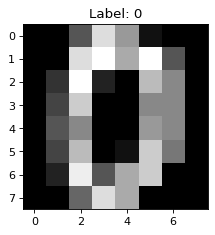

In [ ]:
from sklearn.datasets import load_digits

digits = load_digits()
print('Images shape:', digits.images.shape)   # (1797, 8, 8) -- 1797 images, each 8x8 pixels
print('Data shape:  ', digits.data.shape)     # (1797, 64)   -- each image FLATTENED into 64 features

plt.figure(figsize=(3, 3))
plt.imshow(digits.images[0], cmap='gray')
plt.title(f'Label: {digits.target[0]}')
plt.show()


Notice: `digits.data` is just `digits.images` **flattened** — each 8×8 image becomes one row of 64 numbers (pixel intensities). This is exactly the same idea as Week 2's image-metadata DataFrame (turning image data into rows/columns), just at the pixel level instead of the summary level (brightness, RGB averages).

### Student Practice — build and evaluate a digit classifier

1. Split `digits.data`/`digits.target` into train/test (`stratify=digits.target`, same as Part 2).
2. Scale with `StandardScaler` — fit on train only, same discipline as before.
3. Fit a `KNeighborsClassifier` with a K of your choice.
4. Print test accuracy and show the confusion matrix.
5. Find and display (with `plt.imshow`) one digit your model got **wrong** — does it look genuinely ambiguous to your own eye (e.g. a messy 4 that looks like a 9)?


Digits test accuracy (k=3): 0.9796296296296296
Number of test images: 540
Number of wrong predictions: 11
K = 1 -> test accuracy: 0.9796
K = 5 -> test accuracy: 0.9852
K = 15 -> test accuracy: 0.9741


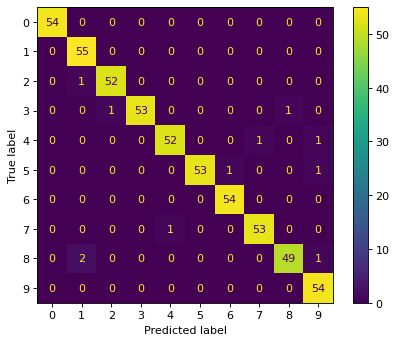

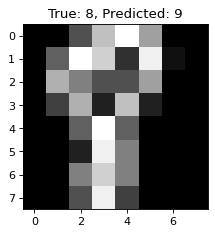

In [ ]:
# 1. Split into train and test (stratify so every digit appears in both)
X_d_train, X_d_test, y_d_train, y_d_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# 2. Scale - fit on train only, then transform both
scaler_d = StandardScaler()
X_d_train_scaled = scaler_d.fit_transform(X_d_train)
X_d_test_scaled = scaler_d.transform(X_d_test)

# 3. Fit KNN (I chose K=3)
knn_d = KNeighborsClassifier(n_neighbors=3)
knn_d.fit(X_d_train_scaled, y_d_train)

# 4. Test accuracy and confusion matrix
y_d_pred = knn_d.predict(X_d_test_scaled)
print('Digits test accuracy (k=3):', accuracy_score(y_d_test, y_d_pred))
print('Number of test images:', len(y_d_test))

ConfusionMatrixDisplay(confusion_matrix(y_d_test, y_d_pred)).plot()
plt.show()

# 5. Show one digit the model got wrong
wrong = np.where(y_d_pred != y_d_test)[0]
print('Number of wrong predictions:', len(wrong))

if len(wrong) > 0:
    i = wrong[0]
    plt.figure(figsize=(3, 3))
    plt.imshow(X_d_test[i].reshape(8, 8), cmap='gray')   # use the unscaled pixels so the image looks normal
    plt.title(f'True: {y_d_test[i]}, Predicted: {y_d_pred[i]}')
    plt.show()

# Extra: compare different K values (used in the reflection below)
for k in [1, 5, 15]:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_d_train_scaled, y_d_train)
    acc = accuracy_score(y_d_test, knn_k.predict(X_d_test_scaled))
    print('K =', k, '-> test accuracy:', round(acc, 4))

*Your answer:* The K=3 model gets about 0.98 test accuracy (11 wrong out of 540 images). The confusion matrix has most counts on the diagonal. The first wrong image is a real **8** that the model predicted as **9**. To my eye this is genuinely ambiguous: the top loop is clear, but the bottom half is just a thin stroke and not a proper loop, so it looks like a 9 with a tail. At only 8x8 pixels, even a person could make the same mistake.

**Reflection:** With 1,797 images instead of 3–5, does K=1 vs K=5 vs K=15 now show a clearer, more trustworthy pattern than it would have on your tiny self-uploaded set? Why does sample size matter here in exactly the same way it mattered for the t-test in Week 4?

*Your answer:*

With 1,797 images instead of 3-5, the results are much more trustworthy. The test set now has 540 images, so one wrong image only changes the accuracy by about 0.19%. On a set of 3-5 images, one image would change the accuracy by 20-33%, so any pattern would just be luck.

On the digits data, K=1 gets about 0.980, K=5 gets about 0.985 and K=15 gets about 0.974. The differences are small because KNN already works very well on this dataset, but K=15 is slightly worse, which fits the idea that a very large K starts to over-smooth. I would not claim a big difference between K=1 and K=5, since that is only a few images out of 540.

This is the same idea as the t-test in Week 4. A bigger sample size gives a smaller standard error, so the numbers we measure are more stable and we can trust differences between them. With a tiny sample, a difference can easily come from random chance.

# Mini Project B: Classifying Text by Topic with KNN (NLP Track — building on Week 1's vectors)

In Week 1 you built bag-of-words vectors from scratch with NumPy and compared sentences using cosine similarity. KNN classification is the natural next step: if two documents' word-vectors are *close*, they're probably about the same topic.

### Demo: bag-of-words vectors for short labeled sentences


In [ ]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

# Build vocabulary (same idea as Week 1's bag-of-words, done manually)
vocab = sorted(set(word for s in sentences for word in s.lower().split()))
print('Vocabulary size:', len(vocab))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])
X_text.shape


Vocabulary size: 29


(6, 29)

### Student Practice — classify a new sentence

1. Fit a `KNeighborsClassifier` (try K=1 or K=3, since we only have 6 training sentences — discuss why a large K wouldn't make sense here) on `X_text`/`labels`.
2. Convert a **new sentence you write yourself** (e.g. `'the striker scored a goal'`) into a vector using the same `to_vector(sentence, vocab)` function.
3. Predict its topic. Does it match what you'd expect?
4. Try a deliberately ambiguous sentence that mixes two topics — what does the model predict, and does that expose a limitation of bag-of-words (it only counts words, it doesn't understand meaning)?


In [ ]:
# 1. Fit KNN on the 6 training sentences (K=1, because we only have 6 sentences)
knn_text = KNeighborsClassifier(n_neighbors=1)
knn_text.fit(X_text, labels)

# 2. Convert a new sentence into a vector with the same vocab
new_sentence = 'the striker scored a goal'
new_vec = to_vector(new_sentence, vocab).reshape(1, -1)

# 3. Predict its topic
print('Sentence:', new_sentence)
print('Predicted topic (K=1):', knn_text.predict(new_vec)[0])
nearest = knn_text.kneighbors(new_vec)[1][0][0]
print('Closest training sentence:', sentences[nearest])

# Same sentence with K=3, to compare
knn_text3 = KNeighborsClassifier(n_neighbors=3)
knn_text3.fit(X_text, labels)
print('Predicted topic (K=3):', knn_text3.predict(new_vec)[0])

# 4. A mixed-topic sentence (tech + cooking)
mixed_sentence = 'the new phone and the pasta'
mixed_vec = to_vector(mixed_sentence, vocab).reshape(1, -1)
print()
print('Sentence:', mixed_sentence)
print('Predicted topic (K=1):', knn_text.predict(mixed_vec)[0])
nearest = knn_text.kneighbors(mixed_vec)[1][0][0]
print('Closest training sentence:', sentences[nearest])

Sentence: the striker scored a goal
Predicted topic (K=1): sports
Closest training sentence: the batsman scored a century today
Predicted topic (K=3): cooking

Sentence: the new phone and the pasta
Predicted topic (K=1): cooking
Closest training sentence: chop the onions and boil the pasta


*Your answer:*
- **Why not a large K:** we have only 6 training sentences (2 per topic), so K should be 1 or at most 3. A bigger K would pull in sentences from other topics.
- **New sentence** ('the striker scored a goal'): K=1 predicts **sports**, which is what I expected. But the reason is only the shared words 'the', 'scored' and 'a' with the batsman sentence, because 'striker' and 'goal' are not in the vocabulary at all. Also, with K=3 it predicts **cooking**, which is wrong, because with 2 sentences per topic, K=3 must include a sentence from another topic.
- **Mixed sentence** ('the new phone and the pasta'): the model predicts **cooking**, even though two of its three content words ('new', 'phone') are about tech. The closest sentence is the cooking one, mostly because of common words like 'the' and 'and'.
- **Limitation of bag-of-words:** it only counts words. It treats 'the' and 'and' as important as 'pasta' or 'phone', it ignores words it has never seen, and it does not understand meaning (it does not know that 'striker' and 'goal' are sports words).

**Reflection:** With only 6 training sentences, why would K=5 or K=6 be a bad choice here, no matter how well it scored on this tiny set? Connect this back to the bias-variance discussion from Part 3 — this is the same principle showing up in a completely different kind of data (text instead of numbers/pixels).

*Your answer:*

With only 6 training sentences (2 per topic), a large K breaks the voting. At K=6 every sentence votes, so each topic gets exactly 2 votes and it is always a tie. At K=5, a topic can get at most 2 votes (it only has 2 sentences), so the winner is decided by ties and not by the real topic. Even if the score looked fine on this tiny set, the prediction would not mean anything.

This links to Part 3. A K that is too large is the high-bias, underfitting side: the model averages over too many points, including ones from other topics, and loses the real pattern. A K that is very small is the high-variance side. So the same principle shows up in text data. K must be small compared to the number of training examples in each class.

## Summary

| What we did | Why it matters |
|---|---|
| Euclidean / Manhattan / Minkowski distance | The mechanism every distance-based method (KNN, clustering) relies on |
| KNN classifier, split-then-scale | Same leakage discipline as Week 5, now applied to a classifier |
| K sweep | Low K = overfitting (high variance); high K = underfitting (high bias) — same shape as Week 6's bias-variance curve, different knob |
| Hand-worked numerical problem | Exam-style practice — you should be able to do this without code |
| Mini Project A (Image) | KNN on real, large-scale image data (digits) — finally enough samples to trust the pattern |
| Mini Project B (NLP) | KNN on text vectors — same algorithm, completely different kind of data |

**Next week:** Decision Trees (ID3) — a completely different way of drawing a decision boundary, and your first look at feature-based (rather than distance-based) classification.
